# Results summary: market-neutral stock ranking with machine learning

This notebook summarizes the results of the model. It does not train anything itself, it only reads the
tables and charts that the model script saves in the `results` folder.

**To update it:** run the model script first, then *Restart & Run All* here.

In [10]:
import os
import pandas as pd
import numpy as np
from IPython.display import Image, display

results_folder='results'
main_strategy='Random Forest'   # strategy the summary focuses on (name used in backtest_summary.csv)

# Files written by the model script
needed_files=['backtest_summary.csv','monthly_excess_returns.csv','ic_summary.csv','ic_by_year.csv',
              'feature_ic.csv','quintile_returns.csv','walk_forward_log.csv','rf_feature_importance.csv']
missing=[file for file in needed_files if not os.path.exists(f'{results_folder}/{file}')]
if missing:
    raise FileNotFoundError(f'Missing in {results_folder}/: {missing}. Run the model script first.')

performance_df=pd.read_csv(f'{results_folder}/backtest_summary.csv',index_col=0)
monthly_returns=pd.read_csv(f'{results_folder}/monthly_excess_returns.csv',index_col=0,parse_dates=True)
ic_summary=pd.read_csv(f'{results_folder}/ic_summary.csv',index_col=0)
ic_by_year=pd.read_csv(f'{results_folder}/ic_by_year.csv',index_col=0)
feature_ic=pd.read_csv(f'{results_folder}/feature_ic.csv',index_col=0)
quintiles=pd.read_csv(f'{results_folder}/quintile_returns.csv',index_col=0)
training_log=pd.read_csv(f'{results_folder}/walk_forward_log.csv')
rf_importance=pd.read_csv(f'{results_folder}/rf_feature_importance.csv',index_col=0)
spy_name=[name for name in monthly_returns.columns if name.startswith('SPY')][0]

def show_chart(file_name):
    # Show a chart saved by the model script (skips it with a note if the file isn't there)
    path=f'{results_folder}/{file_name}'
    if os.path.exists(path):
        display(Image(filename=path,width=850))
    else:
        print(f'(chart not found: {path})')

def format_table(table,percent_columns=(),decimal_columns=()):
    # Copy of a table with readable numbers, for display only
    formatted=table.copy()
    for col in percent_columns:
        if col in formatted:
            formatted[col]=formatted[col].map(lambda x: '' if pd.isna(x) else f'{x:.1%}')
    for col in decimal_columns:
        if col in formatted:
            formatted[col]=formatted[col].map(lambda x: '' if pd.isna(x) else f'{x:.2f}')
    return(formatted)

print(f'Test period: {monthly_returns.index.min().date()} to {monthly_returns.index.max().date()} ({len(monthly_returns)} monthly rebalances)')

Test period: 2019-01-02 to 2026-09-10 (93 monthly rebalances)


## 1. Headline result

In [11]:
main=performance_df.loc[main_strategy]
spy=performance_df.loc[spy_name]
print(f'{main_strategy} (beta-neutral long-short, net of costs)')
print(f'  Annual excess return over T-bills: {main["Ann. Excess Return"]:.1%}   (SPY: {spy["Ann. Excess Return"]:.1%})')
print(f'  Sharpe ratio:                      {main["Sharpe Ratio"]:.2f}    (SPY: {spy["Sharpe Ratio"]:.2f})')
print(f'  Max drawdown:                      {main["Max Drawdown"]:.1%}   (SPY: {spy["Max Drawdown"]:.1%})')
print(f'  Beta to SPY:                       {main["Beta to SPY"]:.2f}')
print(f'  Alpha (annual) and t-stat:         {main["Alpha (annual)"]:.1%}, t = {main["Alpha t-stat"]:.2f}')
print(f'  Avg month when SPY was up / down:  {main["Avg SPY-up Month"]:+.2%} / {main["Avg SPY-down Month"]:+.2%}')
print(f'  Correlation with SPY:              {monthly_returns[main_strategy].corr(monthly_returns[spy_name]):.2f}')

Random Forest (beta-neutral long-short, net of costs)
  Annual excess return over T-bills: 6.5%   (SPY: 14.4%)
  Sharpe ratio:                      0.79    (SPY: 0.84)
  Max drawdown:                      -9.4%   (SPY: -22.6%)
  Beta to SPY:                       -0.02
  Alpha (annual) and t-stat:         6.9%, t = 2.22
  Avg month when SPY was up / down:  +0.42% / +0.82%
  Correlation with SPY:              -0.03


## 2. Portfolio performance

All strategies hold 10 stocks long and 10 short, rebalance every 21 trading days, and are beta-neutral
(except SPY). Returns are above T-bills and after transaction costs. Alpha and beta come from a regression
of monthly returns on SPY.

,Ann. Excess Return,Ann. Volatility,Sharpe Ratio,Max Drawdown,Beta to SPY,Alpha (annual),Alpha t-stat,Avg SPY-up Month,Avg SPY-down Month,Avg Turnover
Strategy,,,,,,,,,,
Random Forest,6.5%,8.4%,0.79,-9.4%,-0.02,6.9%,2.22,0.4%,0.8%,1.21
Random Forest (max Sharpe),2.2%,6.6%,0.37,-8.6%,-0.02,2.8%,1.14,0.2%,0.2%,1.37
Ridge,-1.5%,9.4%,-0.11,-16.9%,0.01,-1.2%,-0.34,-0.1%,-0.1%,1.53
Momentum 12-1,2.5%,15.7%,0.24,-32.3%,-0.12,5.6%,0.97,0.4%,0.2%,0.61
Reversal 1M,-4.5%,12.2%,-0.32,-42.0%,0.10,-5.4%,-1.20,-0.1%,-0.7%,1.78
Low Volatility,-8.1%,13.0%,-0.58,-52.5%,-0.24,-3.9%,-0.85,-1.2%,0.4%,0.55
SPY (buy & hold),14.4%,18.2%,0.84,-22.6%,1.00,0.0%,,4.2%,-4.3%,


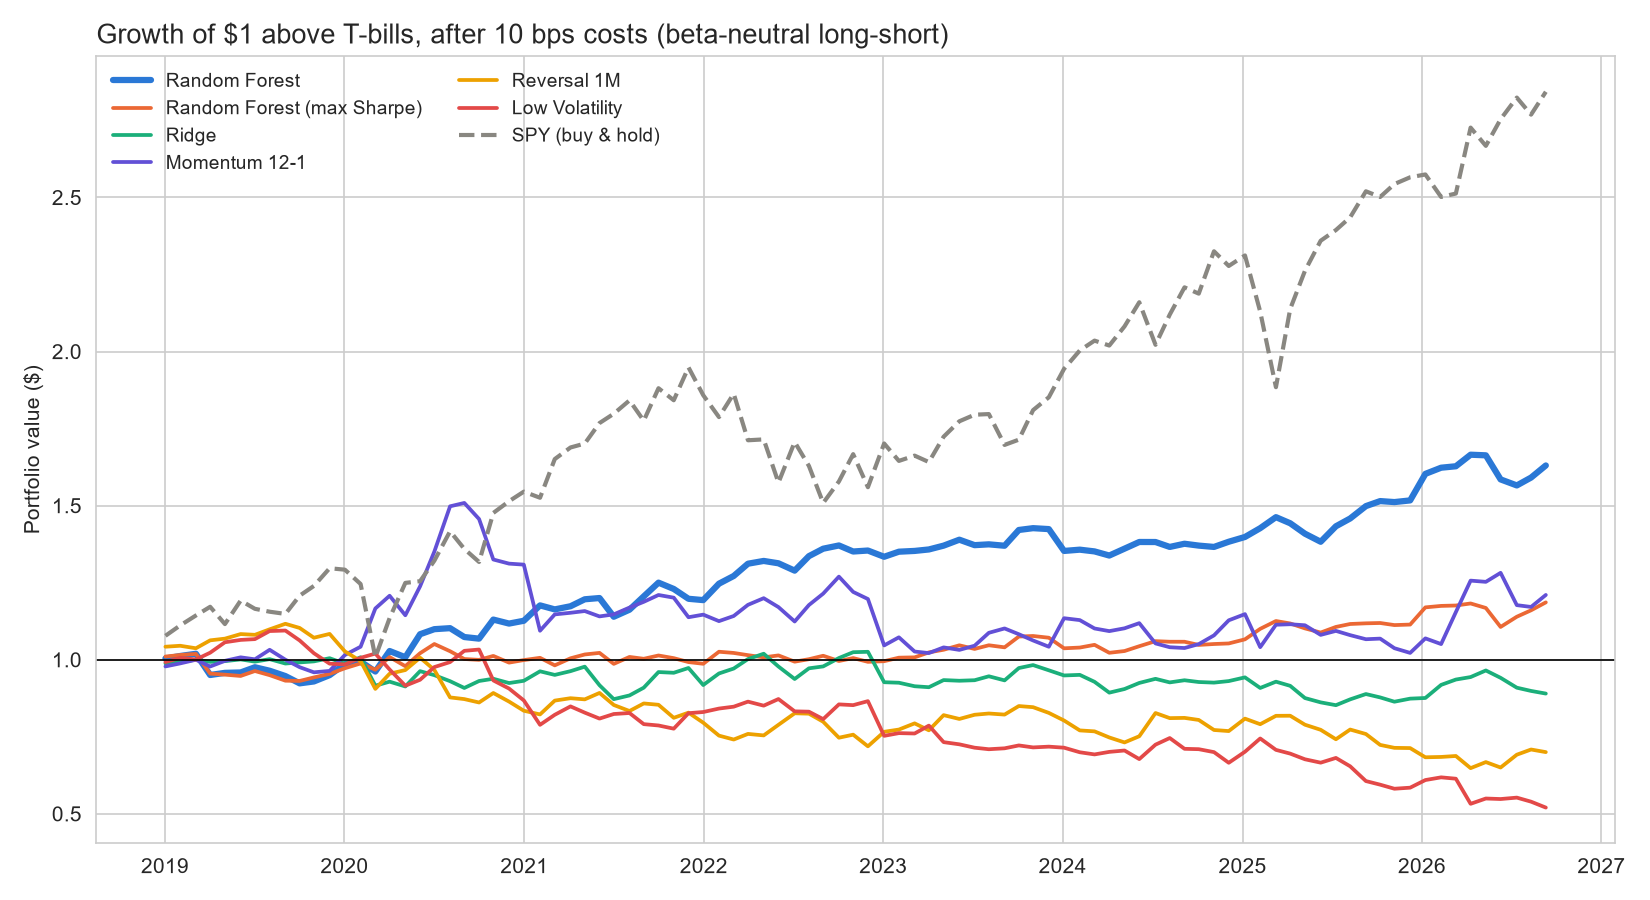

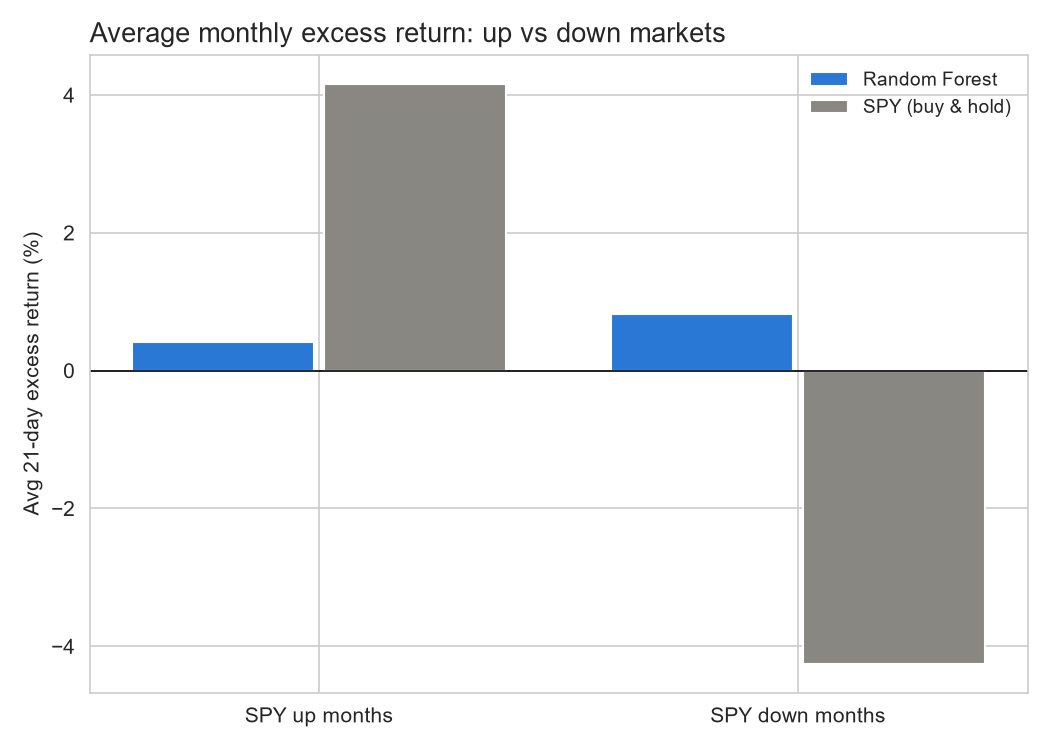

In [12]:
display(format_table(performance_df,
                     percent_columns=['Ann. Excess Return','Ann. Volatility','Max Drawdown','Alpha (annual)','Avg SPY-up Month','Avg SPY-down Month'],
                     decimal_columns=['Sharpe Ratio','Beta to SPY','Alpha t-stat','Avg Turnover']))
show_chart('equity_curves.png')
show_chart('up_down_months.png')

In [13]:
# Calendar-year returns (first and last years are partial)
yearly_returns=(1+monthly_returns).groupby(monthly_returns.index.year).prod()-1
yearly_returns.index.name='Year'
display(yearly_returns.map(lambda x: f'{x:.1%}'))

,Random Forest,Random Forest (max Sharpe),Ridge,Momentum 12-1,Reversal 1M,Low Volatility,SPY (buy & hold)
Year,,,,,,,
2019,-5.0%,-4.6%,0.5%,-3.6%,8.4%,-1.3%,29.7%
2020,18.6%,4.7%,-7.3%,35.8%,-23.0%,-12.1%,19.2%
2021,6.0%,-1.2%,-1.5%,-12.4%,-4.7%,-4.3%,20.3%
2022,13.5%,0.6%,11.7%,4.4%,-9.6%,4.3%,-16.1%
2023,5.1%,7.9%,-5.9%,-12.9%,15.1%,-17.1%,18.7%
2024,-2.9%,-1.7%,-3.6%,8.2%,-7.1%,-7.3%,23.0%
2025,9.7%,5.8%,-6.1%,-9.4%,-7.2%,-12.1%,12.6%
2026,7.5%,6.5%,1.9%,18.4%,-1.8%,-11.0%,10.8%


## 3. How robust is the main result?

A strong-looking backtest can come from a few lucky months. These checks look at how much the result
depends on the best months and on the time period.

In [14]:
returns=monthly_returns[main_strategy]
sharpe_func=lambda x: x.mean()/x.std()*np.sqrt(12)
half=len(returns)//2
robustness={'Sharpe ratio (all months)':sharpe_func(returns),
            'Sharpe without best 1 month':sharpe_func(returns.drop(returns.nlargest(1).index)),
            'Sharpe without best 3 months':sharpe_func(returns.drop(returns.nlargest(3).index)),
            'Sharpe without best 5 months':sharpe_func(returns.drop(returns.nlargest(5).index)),
            'Sharpe, first half of test period':sharpe_func(returns.iloc[:half]),
            'Sharpe, second half of test period':sharpe_func(returns.iloc[half:]),
            '% of months positive':(returns>0).mean()*100,
            '% of calendar years positive':(yearly_returns[main_strategy]>0).mean()*100}
display(pd.Series(robustness,name=main_strategy).round(2).to_frame())
print('Best 5 months:')
display(returns.nlargest(5).map(lambda x: f'{x:.1%}').to_frame())

,Random Forest
Sharpe ratio (all months),0.79
Sharpe without best 1 month,0.72
Sharpe without best 3 months,0.56
Sharpe without best 5 months,0.41
"Sharpe, first half of test period",0.88
"Sharpe, second half of test period",0.70
% of months positive,62.37
% of calendar years positive,75.00


Best 5 months:


,Random Forest
Date,
2020-06-03,7.4%
2020-04-02,6.9%
2020-10-30,5.8%
2026-01-08,5.7%
2022-02-01,4.5%


## 4. Signal quality: Information Coefficient (IC)

IC is the rank correlation between a signal and the stocks' actual next-month residual return
(after removing beta and sector), calculated each month. Around 0.02 to 0.05 is considered useful.

- **t-stat:** is the average IC different from zero? Roughly above 2 is significant.
- **t-stat (NW):** Newey-West version, which allows for month-to-month autocorrelation. More conservative.

,Mean IC,IC Std,t-stat,t-stat (NW),% Months IC>0
Signal,,,,,
Random Forest,0.011,0.110,1.01,0.97,50.5%
Ridge,0.018,0.123,1.41,1.73,57.0%
Momentum 12-1,-0.005,0.179,-0.28,-0.34,50.5%
Reversal 1M,0.006,0.133,0.41,0.40,51.6%
Low Volatility,-0.012,0.140,-0.82,-0.79,45.2%


Mean IC by year:


,Random Forest,Ridge,Momentum 12-1,Reversal 1M,Low Volatility
Year,,,,,
2019,-0.010,-0.005,-0.012,0.038,0.012
2020,0.073,0.037,0.016,-0.066,-0.017
2021,0.023,0.035,-0.059,-0.010,0.021
2022,0.041,0.046,-0.029,-0.005,0.022
2023,0.018,0.029,0.009,0.073,-0.055
2024,-0.044,-0.011,0.009,-0.023,0.008
2025,-0.029,-0.001,-0.011,-0.012,-0.085
2026,0.018,0.011,0.044,0.073,0.008


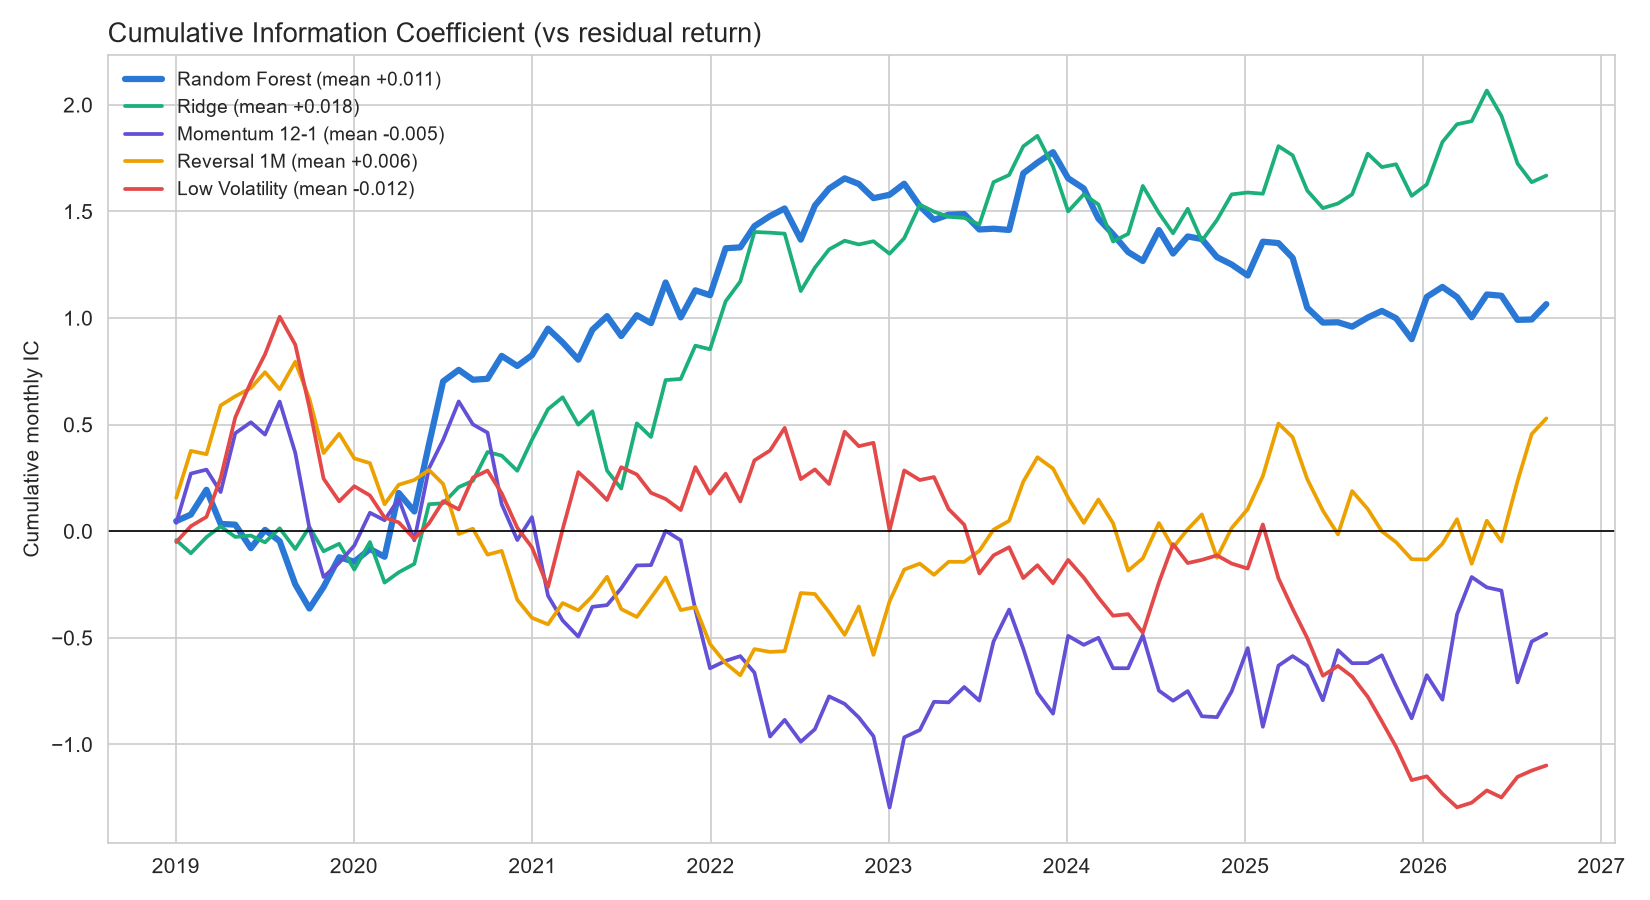

In [15]:
display(format_table(ic_summary,percent_columns=['% Months IC>0'],decimal_columns=['t-stat','t-stat (NW)']).round(3))
print('Mean IC by year:')
display(ic_by_year.round(3))
show_chart('cumulative_ic.png')

## 5. Quintile analysis

Each month, stocks are split into five groups by the model's prediction. A good ranking model shows
residual returns rising from Q1 (predicted worst) to Q5 (predicted best).

,"Random Forest (avg residual return, %)","Ridge (avg residual return, %)"
Quintile,,
1,-0.24,-0.25
2,0.05,0.01
3,-0.15,-0.01
4,-0.10,-0.08
5,0.43,0.32


Random Forest: Q5 - Q1 spread = 0.67% per month
Ridge: Q5 - Q1 spread = 0.57% per month


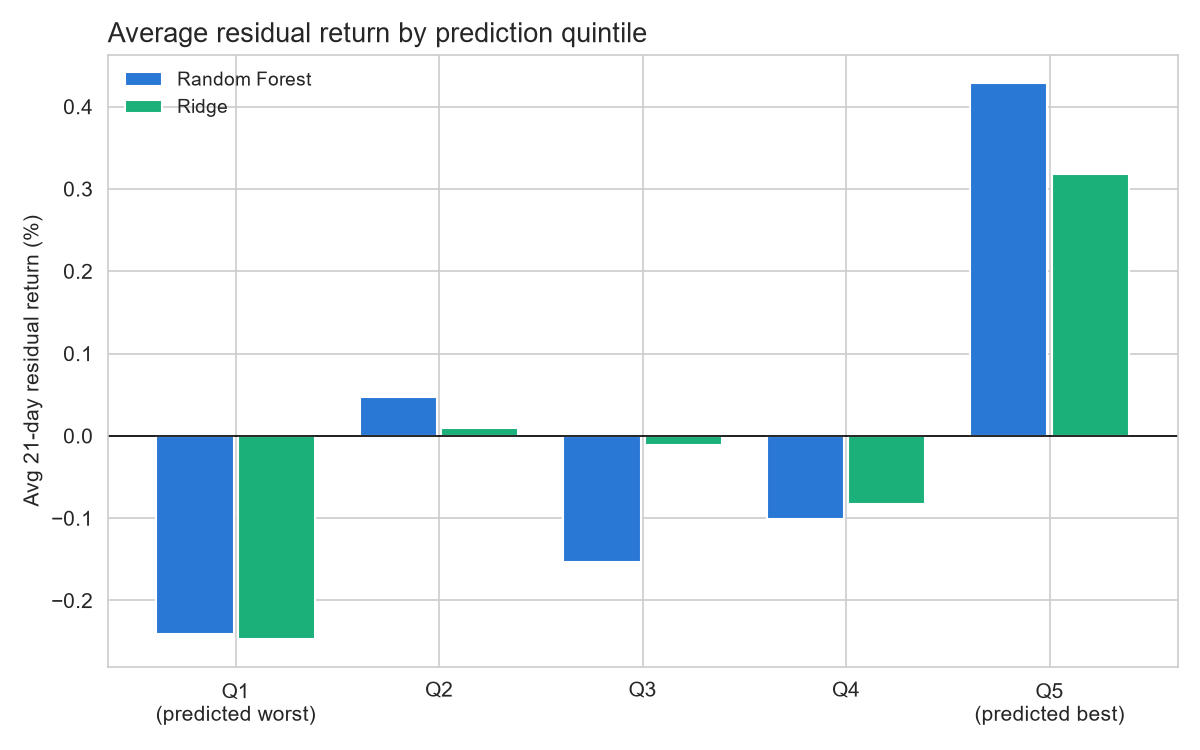

In [16]:
display((quintiles*100).round(2).rename(columns=lambda name: f'{name} (avg residual return, %)'))
for name in quintiles.columns:
    print(f'{name}: Q5 - Q1 spread = {(quintiles[name].iloc[-1]-quintiles[name].iloc[0])*100:.2f}% per month')
show_chart('quintile_returns.png')

## 6. Features

Single-feature IC shows how well each feature ranks stocks on its own, against raw returns and against
residual returns. Features whose IC mostly disappears after removing beta and sector were capturing market
exposure, not stock-specific performance.

,IC vs Raw Return,IC vs Residual Return,RF Importance (avg)
Feature,,,
Volume_Ratio,0.0360,0.0124,0.0412
Volatility_63,0.0539,0.0118,0.0873
High-low_range,0.0442,0.0098,0.0564
Volatility_21,0.0514,0.0091,0.0419
Max_Return_21,0.0468,0.0079,0.0422
MA_Ratio_200,0.0053,0.0011,0.1010
Volume_Momentum,-0.0053,-0.0011,0.0517
Beta_63,0.0458,-0.0019,0.0800
Momentum_5,-0.0039,-0.0048,0.0346


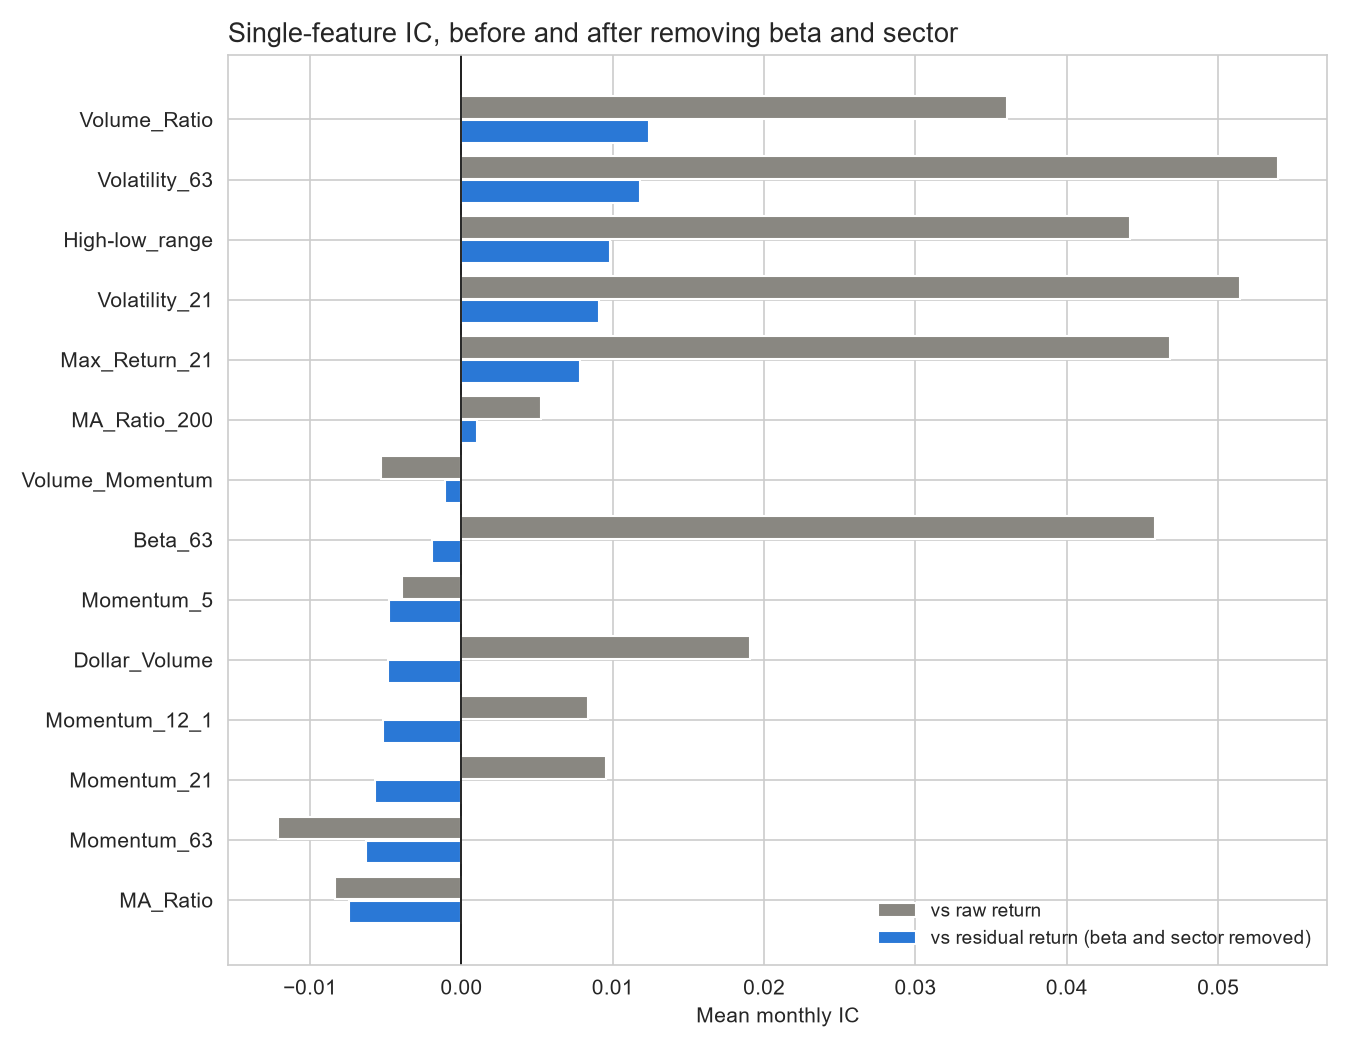

In [17]:
feature_table=feature_ic.copy()
feature_table['RF Importance (avg)']=rf_importance.mean(axis=1)
display(feature_table.sort_values('IC vs Residual Return',ascending=False).round(4))
show_chart('feature_ic.png')

## 7. Walk-forward training log

One set of models per test year, each trained only on data available before that year
(with a 21-day embargo between training and test data).

In [18]:
display(training_log)

,Test Year,Train From,Train To,Train Rows,Ridge Degree,Ridge Alpha,CV IC
0,2019,2013-01-09,2018-11-23,30509,2,1,0.0218
1,2020,2013-01-09,2019-11-29,35762,1,10000,0.0054
2,2021,2013-01-09,2020-11-25,40912,2,10,0.0171
3,2022,2013-01-09,2021-12-01,46165,2,100000,0.0221
4,2023,2013-01-09,2022-11-29,51315,2,10000,0.0210
5,2024,2013-01-09,2023-11-28,56465,2,100000,0.0223
6,2025,2013-01-09,2024-11-25,61615,2,100000,0.0209
7,2026,2013-01-09,2025-11-25,66765,2,100000,0.0195


## 8. Blending the strategy with SPY

Because the strategy has almost no correlation with the market, it can work as a diversifying satellite next to an index fund. This compares SPY on its own with SPY blended with the main strategy. The blend weights are only an illustration and were picked after seeing the results.

,Ann. Excess Return,Ann. Volatility,Sharpe Ratio,Max Drawdown,Worst Month
100% SPY / 0% Random Forest,14.4%,18.2%,0.84,-22.6%,-19.1%
80% SPY / 20% Random Forest,13.2%,14.6%,0.93,-18.2%,-15.9%
70% SPY / 30% Random Forest,12.5%,12.9%,0.98,-16.3%,-14.3%


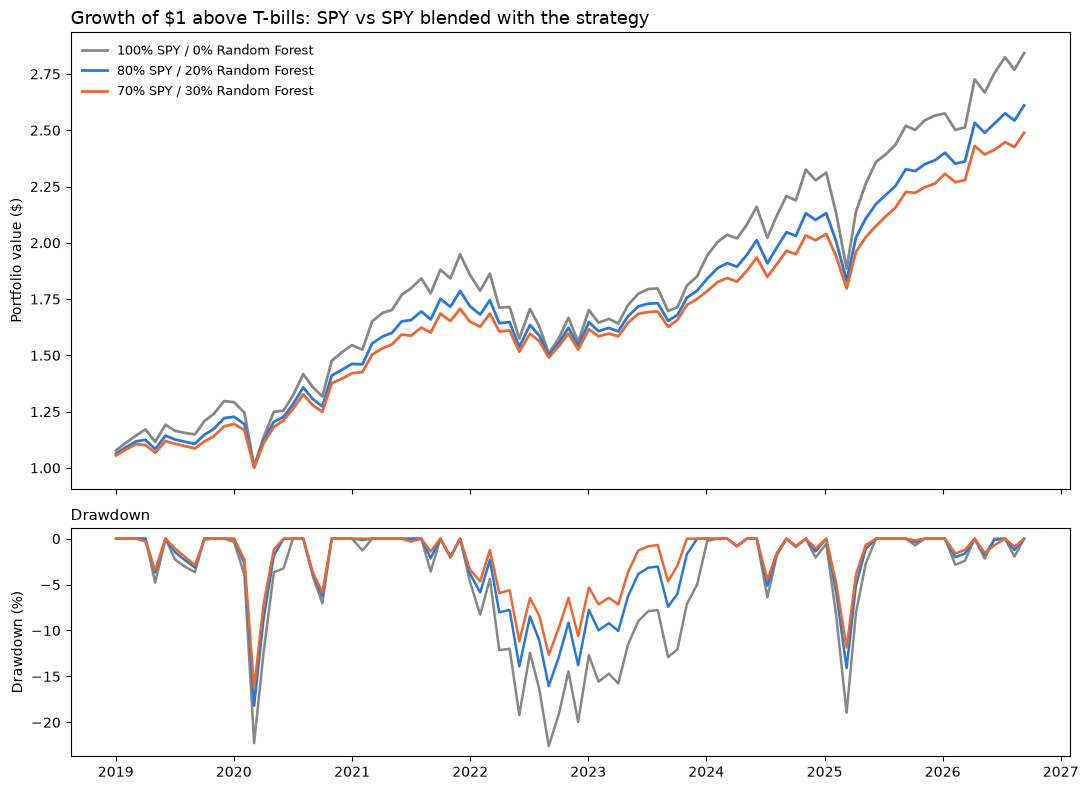

In [19]:
from matplotlib import pyplot as plt

blend_weights=[0,0.2,0.3]   # share of the portfolio in the main strategy, the rest in SPY
blend_returns=pd.DataFrame({f'{int((1-w)*100)}% SPY / {int(w*100)}% {main_strategy}':(1-w)*monthly_returns[spy_name]+w*monthly_returns[main_strategy]
                            for w in blend_weights})

# Summary table
blend_value=(1+blend_returns).cumprod()
blend_summary=pd.DataFrame({'Ann. Excess Return':blend_value.iloc[-1]**(12/len(blend_returns))-1,
                            'Ann. Volatility':blend_returns.std()*np.sqrt(12),
                            'Sharpe Ratio':blend_returns.mean()/blend_returns.std()*np.sqrt(12),
                            'Max Drawdown':(blend_value/blend_value.cummax()-1).min(),
                            'Worst Month':blend_returns.min()})
display(format_table(blend_summary,percent_columns=['Ann. Excess Return','Ann. Volatility','Max Drawdown','Worst Month'],decimal_columns=['Sharpe Ratio']))

# Growth of $1 and drawdown
fig,axes=plt.subplots(2,1,figsize=(11,8),sharex=True,gridspec_kw={'height_ratios':[2,1]})
for name,color in zip(blend_returns.columns,['#898781','#2a78d6','#eb6834']):
    axes[0].plot(blend_value[name],color=color,linewidth=2,label=name)
    axes[1].plot((blend_value[name]/blend_value[name].cummax()-1)*100,color=color,linewidth=1.8)
axes[0].set_title('Growth of $1 above T-bills: SPY vs SPY blended with the strategy',loc='left',fontsize=13)
axes[0].set_ylabel('Portfolio value ($)')
axes[0].legend(frameon=False,fontsize=9)
axes[1].set_title('Drawdown',loc='left',fontsize=11)
axes[1].set_ylabel('Drawdown (%)')
plt.tight_layout()
plt.show()

## Notes and limitations

- **Survivorship bias:** the universe is today's large-cap stocks, so companies that shrank or were delisted
  since 2012 are missing. This likely makes historical results look better than they really were.
- **Multiple testing:** several strategies were compared. One of them reaching t approximately 2 can happen by chance,
  so a single significant result should be treated with caution.
- **Simplified trading:** trades at the closing price on the rebalance day, flat 10 bps cost on turnover,
  no short-borrowing fees, and weights are not adjusted during the month.
- **Short test period:** about 8 years of monthly data, so all statistics have wide error bars.
- **Not investment advice.** This is a research project.